# Фурье, вейвлеты и Френель: три способа разложить сигнал

Каждое линейное преобразование — это выбор **базиса**: набора эталонных сигналов, по которым сигнал раскладывается, $x=\sum_kc_k\,\psi_k$, $c_k=\langle x,\psi_k\rangle$. Если базис ортонормированный, энергия сохраняется (Парсеваль), а обратное преобразование — та же операция с сопряжёнными функциями. Разница между преобразованиями — только в том, **какие** функции $\psi_k$ взяты, и это решает всё: для каких сигналов коэффициентов мало, что легко увидеть, что легко отфильтровать.

| | базисная функция | что «видит» | где в серии |
|---|---|---|---|
| **Фурье** | синусоида $e^{j2\pi kn/N}$, бесконечная во времени | частоту, но не момент | OFDM (`ofdm_sim`, `lte_sim`), Δf-сетка OTFS |
| **Вейвлеты** | короткая волна $\psi\big(\frac{t-b}{s}\big)$, сдвинутая и растянутая | частоту и момент; разрешение зависит от частоты | wavelet-OFDM в PLC (IEEE 1901), сжатие JPEG 2000 |
| **Френель** | чирп $e^{-j\pi(n-m)^2/N}$ | скорость изменения частоты | OCDM (`ocdm_sim`), AFDM (`afdm_sim`), LoRa (`lora_sim`), оптика |

Функции Уолша из `otsm_sim` и импульсы Зака из `zak_sim` — ещё два базиса из того же ряда.

1. Фурье: окна, утечка, свёртка · 2. Соотношение неопределённостей и STFT · 3. Непрерывное вейвлет-преобразование · 4. Дискретное вейвлет-преобразование и нулевые моменты · 5. Френель в оптике: дифракция на щели, переход к Фраунгоферу · 6. Дискретный Френель: эффект Тальбота, чирп → дельта · 7. Разреженность и шумоподавление: каждому базису свой сигнал

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.special import fresnel

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
FS = 1000.0            # частота дискретизации тестового сигнала, Гц
N = 2048               # длина тестового сигнала (2.05 с)
W0 = 6.0               # центральная частота вейвлета Морле (добротность)
LAM = 0.633e-6         # длина волны, м (гелий-неоновый лазер)
SLIT_A = 0.5e-3        # полуширина щели, м
GRAT_D = 0.1e-3        # период решётки для эффекта Тальбота, м

rng = np.random.default_rng(SEED)

## Примитивы: тестовый сигнал, STFT, CWT Морле, DWT (банк фильтров Малла, Хаар/db2/db4), DFnT, распространение Френеля

In [2]:
t = np.arange(N) / FS

# ---------- тестовый сигнал: два близких тона, ЛЧМ, два щелчка, короткая вспышка ----------
def test_signal():
    x = np.cos(2 * np.pi * 50 * t) + np.cos(2 * np.pi * 62 * t)
    tc = t - 0.2; on = (tc >= 0) & (tc <= 1.6)
    x += on * np.cos(2 * np.pi * (100 * tc + 0.5 * (300 / 1.6) * tc ** 2))      # ЛЧМ 100 → 400 Гц
    x += 1.5 * np.exp(-((t - 0.3) / 0.01) ** 2) * np.cos(2 * np.pi * 420 * t)    # вспышка 420 Гц, 20 мс
    x[int(0.6 * FS)] += 8; x[int(1.4 * FS)] += 8                                 # щелчки
    return x
f_inst = lambda tt: 100 + 300 / 1.6 * (tt - 0.2)

# ---------- Фурье: STFT ----------
def stft(x, L, hop, nfft=512):
    w = np.hanning(L); idx = np.arange(0, len(x) - L + 1, hop)
    S = np.fft.rfft(x[idx[:, None] + np.arange(L)] * w, n=max(nfft, L), axis=1) / (w.sum() / 2)
    return (idx + L / 2) / FS, np.fft.rfftfreq(max(nfft, L), 1 / FS), np.abs(S).T

# ---------- непрерывное вейвлет-преобразование (Морле) через FFT ----------
def cwt_morlet(x, freqs, w0=W0):
    """нормировка по амплитуде: тон с амплитудой 1 даёт |W| ≈ 1 на своей частоте"""
    X = np.fft.fft(x); om = 2 * np.pi * np.fft.fftfreq(len(x), 1 / FS)
    out = np.empty((len(freqs), len(x)), complex)
    for i, f in enumerate(freqs):
        s = w0 / (2 * np.pi * f)                                  # масштаб, с
        out[i] = np.fft.ifft(X * 2 * np.exp(-(s * om - w0) ** 2 / 2) * (om > 0))
    return out

# ---------- дискретное вейвлет-преобразование: банк фильтров Малла, периодическое продолжение ----------
_s3 = np.sqrt(3)
WAVELETS = {
    "haar": np.array([1, 1]) / np.sqrt(2),
    "db2": np.array([1 + _s3, 3 + _s3, 3 - _s3, 1 - _s3]) / (4 * np.sqrt(2)),
    "db4": np.array([0.2303778133088964, 0.7148465705529154, 0.6308807679298587, -0.0279837694168599,
                     -0.1870348117190931, 0.0308413818355607, 0.0328830116668852, -0.0105974017850690]),
}
def qmf(h):
    return h[::-1] * (-1) ** np.arange(len(h))                    # высокочастотный фильтр из низкочастотного

def dwt_step(x, h):
    g = qmf(h); a = np.zeros(len(x) // 2, x.dtype); d = np.zeros_like(a)
    for n in range(len(h)):
        xs = np.roll(x, -n)[::2]; a = a + h[n] * xs; d = d + g[n] * xs
    return a, d

def idwt_step(a, d, h):
    g = qmf(h); ua = np.zeros(2 * len(a), a.dtype); ud = np.zeros_like(ua); ua[::2] = a; ud[::2] = d
    return sum(np.roll(h[n] * ua + g[n] * ud, n) for n in range(len(h)))

def wavedec(x, wl, lev):
    out = []; a = x
    for _ in range(lev):
        a, d = dwt_step(a, WAVELETS[wl]); out.append(d)
    return [a] + out[::-1]                                        # [a_J, d_J, …, d_1]

def waverec(c, wl):
    a = c[0]
    for d in c[1:]:
        a = idwt_step(a, d, WAVELETS[wl])
    return a

# ---------- Френель ----------
def dfnt(x, alpha=1.0):
    """дискретное преобразование Френеля Φ = Fᴴ·Γ·F, Γ = exp(−jπαk²/N) (как в ocdm_sim; α = 1 — базис OCDM)"""
    n = x.shape[-1]; k = np.arange(n)
    return np.fft.ifft(np.fft.fft(x, axis=-1) * np.exp(-1j * np.pi * alpha * k ** 2 / n), axis=-1)

def idfnt(x, alpha=1.0):
    n = x.shape[-1]; k = np.arange(n)
    return np.fft.ifft(np.fft.fft(x, axis=-1) * np.exp(1j * np.pi * alpha * k ** 2 / n), axis=-1)

def fresnel_prop(u0, dx, z, lam=LAM):
    """параксиальное распространение на расстояние z: умножение спектра на чирп exp(−jπλz·f²)"""
    fx = np.fft.fftfreq(len(u0), dx)
    return np.fft.ifft(np.fft.fft(u0) * np.exp(-1j * np.pi * lam * z * fx ** 2))

# самопроверки: ортонормированность фильтров, полное восстановление, унитарность
for wl, h in WAVELETS.items():
    assert abs(h.sum() - np.sqrt(2)) < 1e-9 and abs(h @ h - 1) < 1e-9, wl
    for m in range(1, len(h) // 2):
        assert abs(h[2 * m:] @ h[:-2 * m]) < 1e-9, (wl, m)
_x = rng.standard_normal(256)
for wl in WAVELETS:
    assert np.allclose(waverec(wavedec(_x, wl, 5), wl), _x)
_z = rng.standard_normal(256) + 1j * rng.standard_normal(256)
assert np.allclose(idfnt(dfnt(_z)), _z) and np.isclose(np.linalg.norm(dfnt(_z)), np.linalg.norm(_z))
X_TEST = test_signal()
print(f"Тестовый сигнал: {N} отсчётов, {N/FS:.2f} с; фильтры Хаара, db2 и db4 ортонормированы, восстановление точное")

Тестовый сигнал: 2048 отсчётов, 2.05 с; фильтры Хаара, db2 и db4 ортонормированы, восстановление точное


## 1. Фурье: окна и утечка
DFT на $N$ отсчётах неявно считает сигнал **периодическим** с периодом $N$. Если тон не укладывается в окно целое число раз, на стыке периодов возникает скачок, и энергия «утекает» по всем бинам. Спектр, который мы видим, — свёртка истинного спектра со спектром окна: $X_w=X*W$. Прямоугольное окно — sinc с боковыми лепестками −13 дБ, спадающими медленно ($1/k$). На расстоянии 30 бинов утечка сильного тона ≈ −40 дБ, и слабый тон на −40 дБ под ней теряется.

Гладкое окно (Ханна, Блэкмана) убирает скачок: лепестки −31 и −58 дБ и быстрый спад. Цена — **шире главный лепесток** (первый ноль на 2 и 3 бинах вместо 1) и больше шумовая полоса ENBW (1.5 и 1.73 бина), то есть хуже разрешение близких тонов и чуть больше шума в бине. Это первый пример компромисса «локализация против подавления», который дальше будет повторяться.

Две теоремы, на которых держится вся цифровая обработка:
* **о свёртке**: свёртка во времени = умножение спектров. Отсюда быстрые фильтры (в десятки раз быстрее уже для 16k отсчётов), эквалайзер OFDM в одно деление и вся связка «канал + CP» в `ofdm_sim`;
* **Парсеваля**: энергия одинакова в обеих областях — ортонормированный базис ничего не теряет и не добавляет.

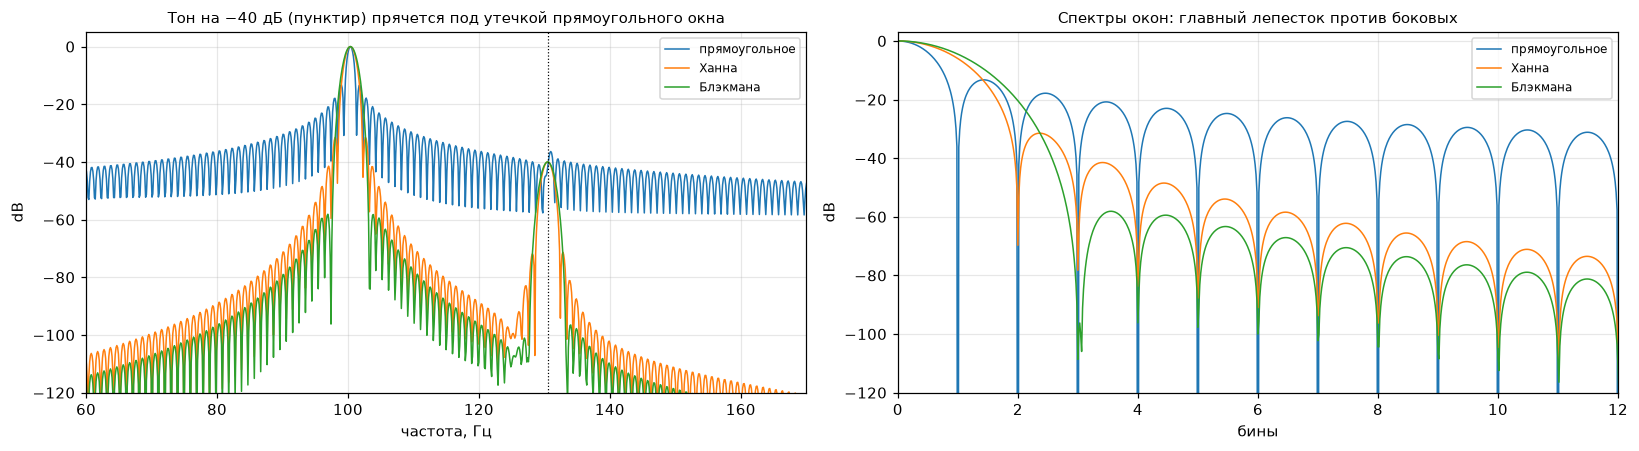

  прямоугольное : боковой лепесток  -13.3 дБ (теория  -13.3), первый ноль 1.00 бина, шумовая полоса ENBW 1.00 бина
  Ханна         : боковой лепесток  -31.5 дБ (теория  -31.5), первый ноль 2.00 бина, шумовая полоса ENBW 1.50 бина
  Блэкмана      : боковой лепесток  -58.1 дБ (теория  -58.1), первый ноль 3.00 бина, шумовая полоса ENBW 1.73 бина
Свёртка 16384 × 8192: напрямую 21 мс, через FFT 0.8 мс (в 26 раз быстрее), max расхождение 3.8e-13
Парсеваль: ‖x‖² = 16205.3690, ‖FFT(x)‖²/N = 16205.3690


In [3]:
# сильный тон не в центре бина и слабый тон на −40 дБ в 30 Гц от него
M1 = 1024; n1 = np.arange(M1)
x1 = np.cos(2 * np.pi * 100.37 * n1 / FS) + 1e-2 * np.cos(2 * np.pi * 130.5 * n1 / FS)
wins = {"прямоугольное": np.ones(M1), "Ханна": np.hanning(M1), "Блэкмана": np.blackman(M1)}
th_sl = {"прямоугольное": -13.26, "Ханна": -31.47, "Блэкмана": -58.11}
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
f1 = np.fft.rfftfreq(8 * M1, 1 / FS)
rows = []
for (nm, w), c in zip(wins.items(), ("C0", "C1", "C2")):
    X = np.abs(np.fft.rfft(x1 * w, 8 * M1)) / (w.sum() / 2)
    ax[0].plot(f1, 20 * np.log10(X + 1e-12), c, lw=1, label=nm)
    W = np.abs(np.fft.rfft(w, 64 * M1)); W /= W[0]; Wd = 20 * np.log10(W + 1e-15)
    first_null = np.argmax(np.diff(Wd) > 0)                          # первый минимум
    sl = Wd[first_null:].max()
    enbw = M1 * np.sum(w ** 2) / w.sum() ** 2
    ax[1].plot(np.arange(len(W)) / 64, Wd, c, lw=1, label=nm)
    rows.append((nm, sl, th_sl[nm], first_null / 64, enbw))
ax[0].axvline(130.5, color="k", ls=":", lw=0.8)
ax[0].set_xlim(60, 170); ax[0].set_ylim(-120, 5); ax[0].set_xlabel("частота, Гц"); ax[0].set_ylabel("dB"); ax[0].legend(fontsize=8)
ax[0].set_title("Тон на −40 дБ (пунктир) прячется под утечкой прямоугольного окна", fontsize=10)
ax[1].set_xlim(0, 12); ax[1].set_ylim(-120, 3); ax[1].set_xlabel("бины"); ax[1].set_ylabel("dB"); ax[1].legend(fontsize=8)
ax[1].set_title("Спектры окон: главный лепесток против боковых", fontsize=10)
plt.tight_layout(); plt.show()
for nm, sl, th, fn, eb in rows:
    print(f"  {nm:14s}: боковой лепесток {sl:6.1f} дБ (теория {th:6.1f}), первый ноль {fn:.2f} бина, шумовая полоса ENBW {eb:.2f} бина")

# теорема о свёртке: O(N log N) против O(N²)
a, b = rng.standard_normal(2 ** 14), rng.standard_normal(2 ** 13)
tt0 = time.perf_counter(); c_dir = np.convolve(a, b); t_dir = time.perf_counter() - tt0
tt0 = time.perf_counter(); L = len(a) + len(b) - 1; c_fft = np.fft.irfft(np.fft.rfft(a, 2 ** 15) * np.fft.rfft(b, 2 ** 15))[:L]; t_fft = time.perf_counter() - tt0
print(f"Свёртка 16384 × 8192: напрямую {t_dir*1e3:.0f} мс, через FFT {t_fft*1e3:.1f} мс (в {t_dir/t_fft:.0f} раз быстрее), max расхождение {np.abs(c_dir - c_fft).max():.1e}")
print(f"Парсеваль: ‖x‖² = {np.sum(a**2):.4f}, ‖FFT(x)‖²/N = {np.sum(np.abs(np.fft.fft(a))**2)/len(a):.4f}")

## 2. Соотношение неопределённостей и STFT
Чтобы увидеть, **когда** звучит частота, берут короткое окно и сдвигают его: кратковременное преобразование Фурье (STFT, спектрограмма). Окно длины $T$ даёт разрешение по частоте ~$1/T$. Произведение среднеквадратичных ширин ограничено снизу:
$$\sigma_t\,\sigma_f\ge\frac1{4\pi},$$
и равенство достигается только на гауссовом окне (проверка: 0.0796 = 1/4π). Ханна и Блэкмана почти на пределе. У прямоугольного окна $\sigma_f$ формально бесконечна: $\int f^2\,\mathrm{sinc}^2f\,df$ расходится из-за медленных лепестков. Это то же соотношение, что в квантовой механике, и та же теорема Балиана–Лоу, из-за которой у OFDM хвосты в спектре (`ofdm_sim`, раздел 1).

Два окна на одном сигнале:
* **32 отсчёта (32 мс)**: щелчки и вспышка — тонкие вертикальные линии, ЛЧМ видна, но тоны 50 и 62 Гц слились в одну широкую полосу (Δf ≈ 62 Гц).
* **256 отсчётов (256 мс)**: тоны разрешены (провал 14.5 дБ), ЛЧМ тонкая, но щелчки размазаны на ±128 мс, а вспышка превратилась в пятно.

Окно STFT выбирается **один раз для всех частот**. Сигналы, где высокие частоты короткие, а низкие длинные (речь, музыка, удары, сейсмика), требуют разного окна на разных частотах. Это и есть вейвлеты.

  гауссово (σ = L/8)    : σ_t·σ_f = 0.0796  (предел 1/4π = 0.0796)
  Ханна                 : σ_t·σ_f = 0.0817  (предел 1/4π = 0.0796)
  Блэкмана              : σ_t·σ_f = 0.0799  (предел 1/4π = 0.0796)
  прямоугольное         : σ_t·σ_f = 1.2240  (предел 1/4π = 0.0796)
  у прямоугольного σ_f растёт с шириной сетки частот: ∫f²·sinc²(f) df расходится


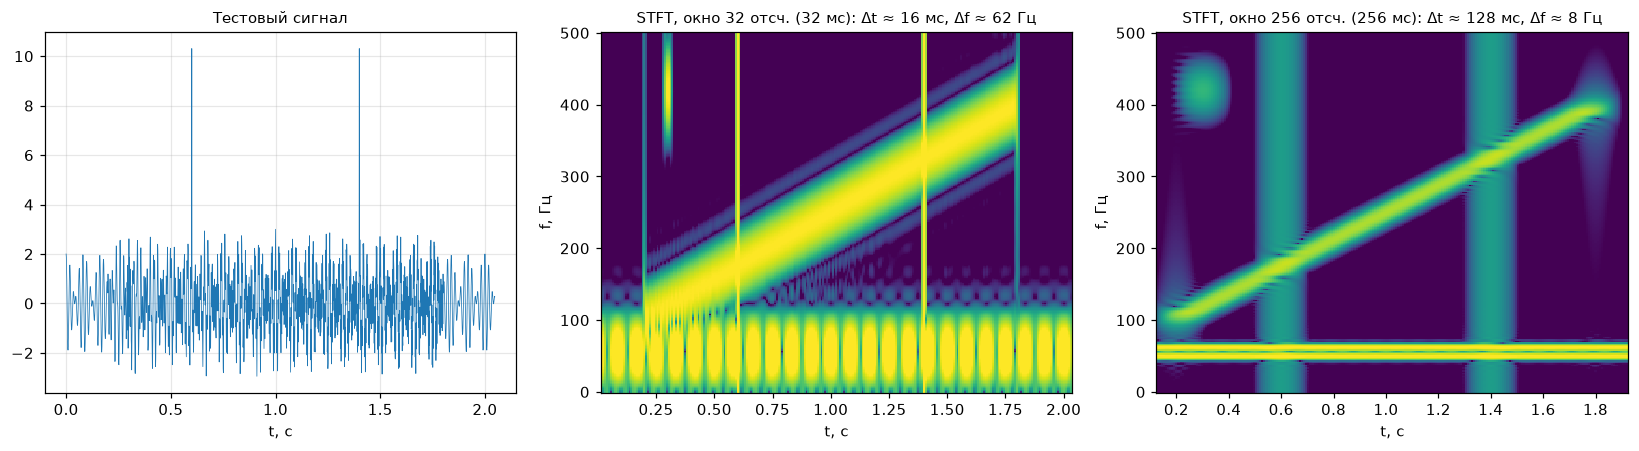

  окно  32: провал между тонами    0.1 дБ → слились
  окно 128: провал между тонами   -2.1 дБ → слились
  окно 256: провал между тонами  -14.5 дБ → разрешены


In [4]:
# соотношение неопределённостей для окон
def spreads(w, pad=64):
    n = np.arange(len(w)) - (len(w) - 1) / 2; e = np.abs(w) ** 2
    st = np.sqrt(np.sum(n ** 2 * e) / e.sum())
    W = np.abs(np.fft.fft(w, pad * len(w))) ** 2; f = np.fft.fftfreq(pad * len(w))
    sf = np.sqrt(np.sum(f ** 2 * W) / W.sum())
    return st, sf
L2 = 256; nn = np.arange(L2) - (L2 - 1) / 2
for nm, w in (("гауссово (σ = L/8)", np.exp(-nn ** 2 / (2 * (L2 / 8) ** 2))), ("Ханна", np.hanning(L2)),
              ("Блэкмана", np.blackman(L2)), ("прямоугольное", np.ones(L2))):
    st, sf = spreads(w)
    print(f"  {nm:22s}: σ_t·σ_f = {st*sf:.4f}  (предел 1/4π = {1/(4*np.pi):.4f})")
print("  у прямоугольного σ_f растёт с шириной сетки частот: ∫f²·sinc²(f) df расходится")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].plot(t, X_TEST, lw=0.5); ax[0].set_xlabel("t, с")
ax[0].set_title("Тестовый сигнал", fontsize=10)
for a_, L in ((ax[1], 32), (ax[2], 256)):
    tt, ff, S = stft(X_TEST, L, 8)
    a_.pcolormesh(tt, ff, 20 * np.log10(S + 1e-3), vmin=-40, vmax=0, shading="auto", cmap="viridis"); a_.grid(False)
    a_.set_xlabel("t, с"); a_.set_ylabel("f, Гц")
    a_.set_title(f"STFT, окно {L} отсч. ({L/FS*1e3:.0f} мс): Δt ≈ {L/FS*1e3/2:.0f} мс, Δf ≈ {2*FS/L:.0f} Гц", fontsize=10)
plt.tight_layout(); plt.show()

# разрешение двух тонов 50 и 62 Гц
for L in (32, 128, 256):
    tt, ff, S = stft(X_TEST, L, 8, nfft=4096); prof = S[:, (tt > 1.85) & (tt < 2.0)].mean(1) if np.any((tt > 1.85) & (tt < 2.0)) else S[:, -1]
    p = prof[(ff >= 45) & (ff <= 67)]; f_ = ff[(ff >= 45) & (ff <= 67)]
    dip = p[(f_ > 54) & (f_ < 58)].min() / min(p[np.argmin(np.abs(f_ - 50))], p[np.argmin(np.abs(f_ - 62))])
    print(f"  окно {L:3d}: провал между тонами {20*np.log10(dip):6.1f} дБ → {'разрешены' if dip < 0.7 else 'слились'}")

## 3. Непрерывное вейвлет-преобразование
Вместо одного окна — одна функция-«волночка» $\psi$, которую сжимают и растягивают:
$$W(s,b)=\frac1{\sqrt s}\int x(t)\,\psi^*\!\Big(\frac{t-b}s\Big)dt .$$
Вейвлет Морле — гауссов импульс с несущей: $\psi(t)=e^{j\omega_0t}e^{-t^2/2}$. На масштабе $s$ он настроен на частоту $f=\omega_0/2\pi s$ и имеет длительность $\sigma_t=s$, а полосу $\sigma_f=f/\omega_0$. **Добротность постоянна**: $f/\sigma_f=\omega_0$. Высокие частоты анализируются коротким окном, низкие — длинным. Клетки частотно-временной плоскости имеют одну площадь (соотношение неопределённостей не обойти), но их форма зависит от частоты (средний и правый рисунки).

На скалограмме:
* **Щелчки** — узкие сверху и широкие снизу. Ширина по полувысоте точно $2.355\,\omega_0/2\pi f$: 7.5 мс на 300 Гц, 90 мс на 25 Гц.
* **ЛЧМ** — гладкая кривая, гребень следует мгновенной частоте с ошибкой 0.6 %.
* **Тоны 50 и 62 Гц** при $\omega_0=6$ не разрешены: полоса на 50 Гц — 8 Гц. Видны биения с разностной частотой 12 Гц. Больший $\omega_0$ разрешит их, но размажет щелчки.

CWT избыточно: здесь 140 масштабов × 2048 сдвигов на 2048 отсчётов. Для анализа это удобно, для сжатия и передачи — нет. Неизбыточный вариант — DWT.

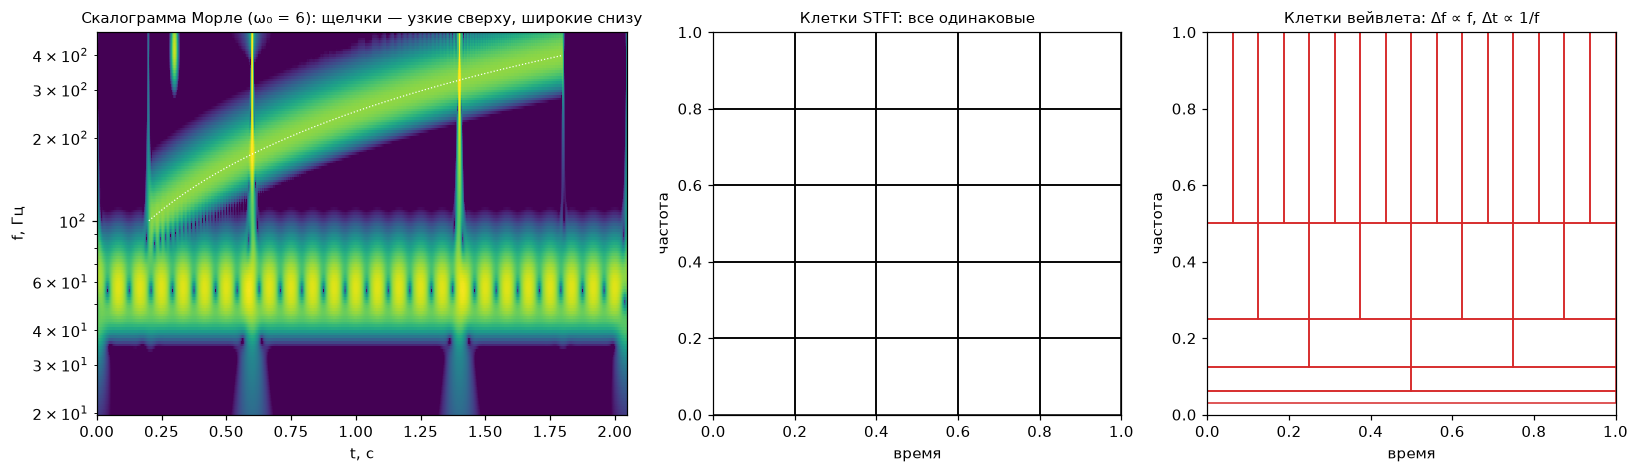

Тон 150 Гц амплитуды 1: |W| на 150 Гц = 1.000
  импульс на   300 Гц: ширина по полувысоте    7.5 мс (теория 2.355·ω₀/2πf =    7.5 мс), полоса σ_f = f/ω₀ =  50.0 Гц
  импульс на   100 Гц: ширина по полувысоте   22.5 мс (теория 2.355·ω₀/2πf =   22.5 мс), полоса σ_f = f/ω₀ =  16.7 Гц
  импульс на    25 Гц: ширина по полувысоте   89.9 мс (теория 2.355·ω₀/2πf =   90.0 мс), полоса σ_f = f/ω₀ =   4.2 Гц
Гребень скалограммы следует мгновенной частоте ЛЧМ: медианная ошибка 0.6 % (шаг сетки частот 2.3 %)
Избыточность: CWT 140×2048 комплексных коэффициентов на 2048 отсчётов — в 140 раз больше данных; DWT (раздел 4) — ровно 2048


In [5]:
FREQS = np.geomspace(20, 480, 140)
Wc = cwt_morlet(X_TEST, FREQS)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.3, 1, 1]})
ax[0].pcolormesh(t, FREQS, 20 * np.log10(np.abs(Wc) + 1e-3), vmin=-30, vmax=6, shading="auto", cmap="viridis"); ax[0].grid(False)
ax[0].set_yscale("log"); ax[0].set_xlabel("t, с"); ax[0].set_ylabel("f, Гц")
ax[0].plot(t[(t > 0.2) & (t < 1.8)], f_inst(t[(t > 0.2) & (t < 1.8)]), "w:", lw=0.8)
ax[0].set_title(f"Скалограмма Морле (ω₀ = {W0:g}): щелчки — узкие сверху, широкие снизу", fontsize=10)

# клетки частотно-временной плоскости
for a_, kind in ((ax[1], "STFT"), (ax[2], "вейвлет")):
    for j in range(5):
        if kind == "STFT":
            h_, w_ = 1 / 5, 1 / 5; y0 = j / 5
            for i in range(5): a_.add_patch(plt.Rectangle((i * w_, y0), w_, h_, fill=False, lw=1))
        else:
            h_ = 2.0 ** -(5 - j); y0 = h_; w_ = 1 / 2 ** j
            for i in range(2 ** j): a_.add_patch(plt.Rectangle((i * w_, y0), w_, h_, fill=False, lw=1, color="C3"))
    a_.set_xlim(0, 1); a_.set_ylim(0, 1); a_.set_xlabel("время"); a_.set_ylabel("частота"); a_.grid(False)
    a_.set_title("Клетки STFT: все одинаковые" if kind == "STFT" else "Клетки вейвлета: Δf ∝ f, Δt ∝ 1/f", fontsize=10)
plt.tight_layout(); plt.show()

# проверки: амплитуда тона, ширина импульса, гребень ЛЧМ
tone = np.cos(2 * np.pi * 150 * t)
print(f"Тон 150 Гц амплитуды 1: |W| на 150 Гц = {np.abs(cwt_morlet(tone, [150.0]))[0, 500:-500].mean():.3f}")
imp = np.zeros(N); imp[N // 2] = 1
for f in (300.0, 100.0, 25.0):
    w = np.abs(cwt_morlet(imp, [f]))[0]; w /= w.max(); tc = np.arange(N) / FS
    tf = np.linspace(tc[0], tc[-1], 40 * N); wf = np.interp(tf, tc, w)
    ab = tf[wf >= 0.5]; fwhm = ab[-1] - ab[0]                              # ширина по полувысоте с интерполяцией
    print(f"  импульс на {f:5.0f} Гц: ширина по полувысоте {fwhm*1e3:6.1f} мс (теория 2.355·ω₀/2πf = {2.355*W0/(2*np.pi*f)*1e3:6.1f} мс), полоса σ_f = f/ω₀ = {f/W0:5.1f} Гц")
sel = (t > 0.45) & (t < 1.75) & (np.abs(t - 0.6) > 0.05) & (np.abs(t - 1.4) > 0.05)
hi = FREQS > 85
ridge = FREQS[hi][np.argmax(np.abs(Wc[hi][:, sel]), 0)]
print(f"Гребень скалограммы следует мгновенной частоте ЛЧМ: медианная ошибка {np.median(np.abs(ridge / f_inst(t[sel]) - 1))*100:.1f} % (шаг сетки частот {(FREQS[1]/FREQS[0]-1)*100:.1f} %)")
print(f"Избыточность: CWT {len(FREQS)}×{N} комплексных коэффициентов на {N} отсчётов — в {len(FREQS)} раз больше данных; DWT (раздел 4) — ровно {N}")

## 4. Дискретное вейвлет-преобразование: банк фильтров
DWT (Малла, Добеши, 1988–89) берёт только масштабы $2^j$ и сдвиги, кратные масштабу, и это ортонормированный базис. Реализация — **пара фильтров и прореживание**: низкочастотный фильтр $h$ даёт грубую версию $a$, высокочастотный $g[n]=(-1)^nh[L-1-n]$ — детали $d$. Оба прореживаются в 2 раза, и с грубой версией шаг повторяется. Отсчётов на выходе ровно столько же, сколько на входе, восстановление точное (ошибка $10^{-14}$), энергия сохраняется. Сложность $O(N)$ — быстрее FFT.

Почему кусочно-гладкий сигнал даёт так мало заметных коэффициентов (101 из 2048 выше 1 % от максимума)? **Нулевые моменты**: у вейвлета Добеши db$p$ выполнено $\sum_nn^kg[n]=0$ для $k<p$. Значит, полином степени ниже $p$ даёт **нулевые** детали. Проверка в таблице: Хаар обнуляет только константы, db2 — ещё и линейные функции, db4 — полиномы до 3-й степени (а 4-я даёт $10^{-9}$). Любой гладкий участок локально почти полином, и детали на нём малы. Крупные коэффициенты остаются только там, где сигнал не гладкий: у скачков и изломов. Их число растёт как логарифм длины, а не как длина. В этом весь секрет JPEG 2000 и вейвлетного шумоподавления (раздел 7).

Фурье на том же сигнале проигрывает: ступенька в спектре спадает как $1/k$, и её коэффициенты распределены по всей полосе.

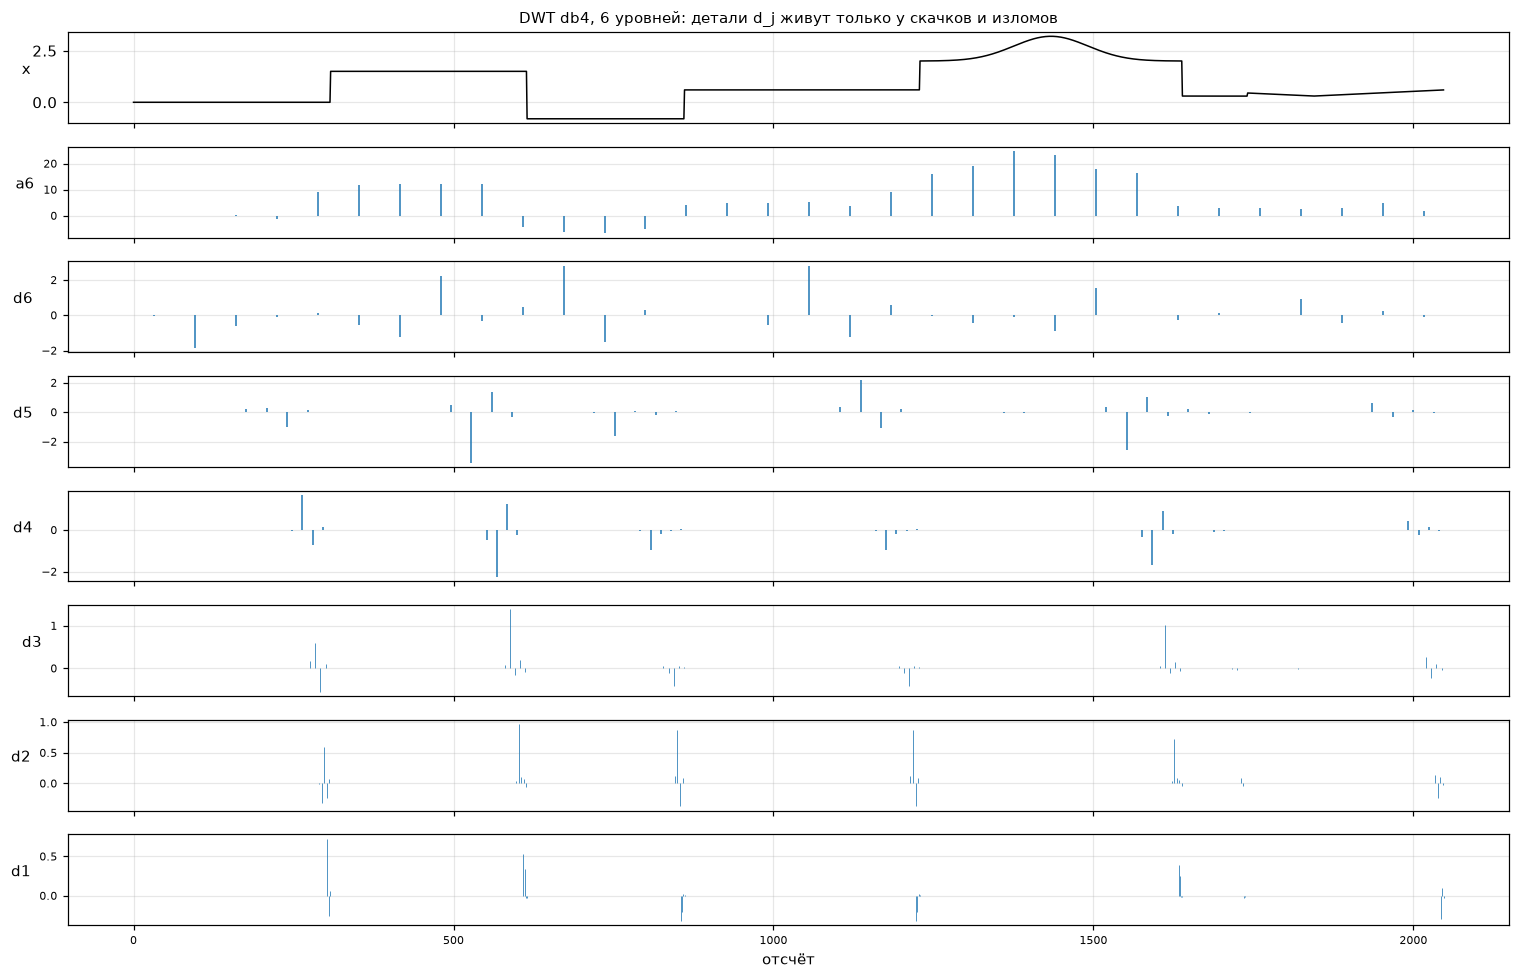

Ортогональность: ‖x‖² = 3531.918000, Σ‖коэфф.‖² = 3531.918000; ошибка восстановления 1.8e-14
Коэффициентов с |c| > 1 % от максимума: 101 из 2048
max|d₁| внутри отрезка для полиномов степени 0…4:
  haar  (1 нулевых момента):  0.0e+00   2.8e-03   5.2e-03   7.3e-03   9.1e-03
  db2   (2 нулевых момента):  1.1e-16   1.7e-16   1.9e-05   5.3e-05   1.0e-04
  db4   (4 нулевых момента):  1.1e-16   2.2e-16   2.5e-16   3.1e-16   2.9e-09


In [6]:
# кусочно-гладкий сигнал: ступени + гладкий горб + излом
def piecewise():
    u = np.arange(N) / N
    y = np.select([u < 0.15, u < 0.3, u < 0.42, u < 0.6, u < 0.8], [0.0, 1.5, -0.8, 0.6, 2.0], 0.3)
    y = y + 1.2 * np.exp(-((u - 0.7) / 0.04) ** 2) + 3 * np.abs(u - 0.9) * (u > 0.85)
    return y
X_PW = piecewise()
LEV = 6
cs = wavedec(X_PW, "db4", LEV)
fig, ax = plt.subplots(LEV + 2, 1, figsize=(14, 9), sharex=True)
ax[0].plot(np.arange(N), X_PW, "k", lw=1); ax[0].set_ylabel("x", rotation=0)
ax[0].set_title(f"DWT db4, {LEV} уровней: детали d_j живут только у скачков и изломов", fontsize=10)
names = [f"a{LEV}"] + [f"d{j}" for j in range(LEV, 0, -1)]
for a_, c, nm in zip(ax[1:], cs, names):
    pos = (np.arange(len(c)) + 0.5) * N / len(c)
    a_.vlines(pos, 0, c, lw=1 if len(c) < 200 else 0.5); a_.set_ylabel(nm, rotation=0, labelpad=12); a_.tick_params(labelsize=7)
ax[-1].set_xlabel("отсчёт")
plt.tight_layout(); plt.show()

allc = np.concatenate(cs)
print(f"Ортогональность: ‖x‖² = {np.sum(X_PW**2):.6f}, Σ‖коэфф.‖² = {np.sum(allc**2):.6f}; ошибка восстановления {np.abs(waverec(cs, 'db4') - X_PW).max():.1e}")
print(f"Коэффициентов с |c| > 1 % от максимума: {np.sum(np.abs(allc) > 0.01*np.abs(allc).max())} из {N}")

# нулевые моменты: полином степени < p даёт нулевые детали (вдали от края периодизации)
u = np.linspace(-1, 1, 512)
print("max|d₁| внутри отрезка для полиномов степени 0…4:")
for wl, p in (("haar", 1), ("db2", 2), ("db4", 4)):
    vals = []
    for deg in range(5):
        _, d = dwt_step(u ** deg, WAVELETS[wl]); vals.append(np.abs(d[8:-8]).max())
    print(f"  {wl:5s} ({p} нулевых момента): " + "  ".join(f"{v:8.1e}" for v in vals))

## 5. Френель в оптике: дифракция на щели
Преобразование Френеля пришло из оптики. Поле за апертурой на расстоянии $z$ в параксиальном приближении:
$$u(x,z)\propto\int u_0(x')\,e^{\,j\pi(x-x')^2/\lambda z}\,dx'=u_0*\text{чирп}\quad\Longleftrightarrow\quad U(f,z)=U_0(f)\,e^{-j\pi\lambda zf^2}.$$
Это **свёртка с чирпом**, или, что то же самое, умножение спектра на квадратичную фазу. Численно это одна пара FFT. Для щели шириной $2a$ есть точный ответ через интегралы Френеля $C(\nu)$, $S(\nu)$, и численный расчёт совпадает с ним: СКО $10^{-5}$–$10^{-4}$ от пика (максимум 2 % у самого края в ближней зоне — там самые мелкие осцилляции).

Режим задаёт **число Френеля** $N_F=a^2/\lambda z$:
* $N_F\gg1$ — ближняя зона: почти геометрическая тень с рябью у краёв;
* $N_F\sim1$ — область Френеля: картина сложная, ни тень, ни спектр;
* $N_F\ll1$ — дальняя зона, **Фраунгофер**: раскрываем квадрат $(x-x')^2=x^2-2xx'+x'^2$, член $x'^2/\lambda z$ на апертуре мал (фаза $\pi N_F$), и интеграл становится **преобразованием Фурье апертуры**: $I\propto\mathrm{sinc}^2(2ax/\lambda z)$. При $N_F=0.5$ отличие от sinc² — 20 %, при $N_F=0.05$ — 0.2 %.

То есть **Фурье — предельный случай Френеля**: дальняя зона и фокальная плоскость линзы — это оптический анализатор спектра. Формально $\text{Френель}=\text{чирп}\cdot\text{Фурье}\cdot\text{чирп}$.

  N_F =    10: z =  0.039 м, ошибка относительно интегралов Френеля: СКО 4.5e-04, max 2.2e-02 от пика; отличие от Фраунгофера nan
  N_F =     2: z =  0.197 м, ошибка относительно интегралов Френеля: СКО 4.7e-05, max 1.8e-03 от пика; отличие от Фраунгофера nan
  N_F =   0.5: z =  0.790 м, ошибка относительно интегралов Френеля: СКО 1.4e-05, max 2.0e-04 от пика; отличие от Фраунгофера 2.0e-01
  N_F =  0.05: z =  7.899 м, ошибка относительно интегралов Френеля: СКО 3.3e-05, max 6.7e-05 от пика; отличие от Фраунгофера 2.2e-03


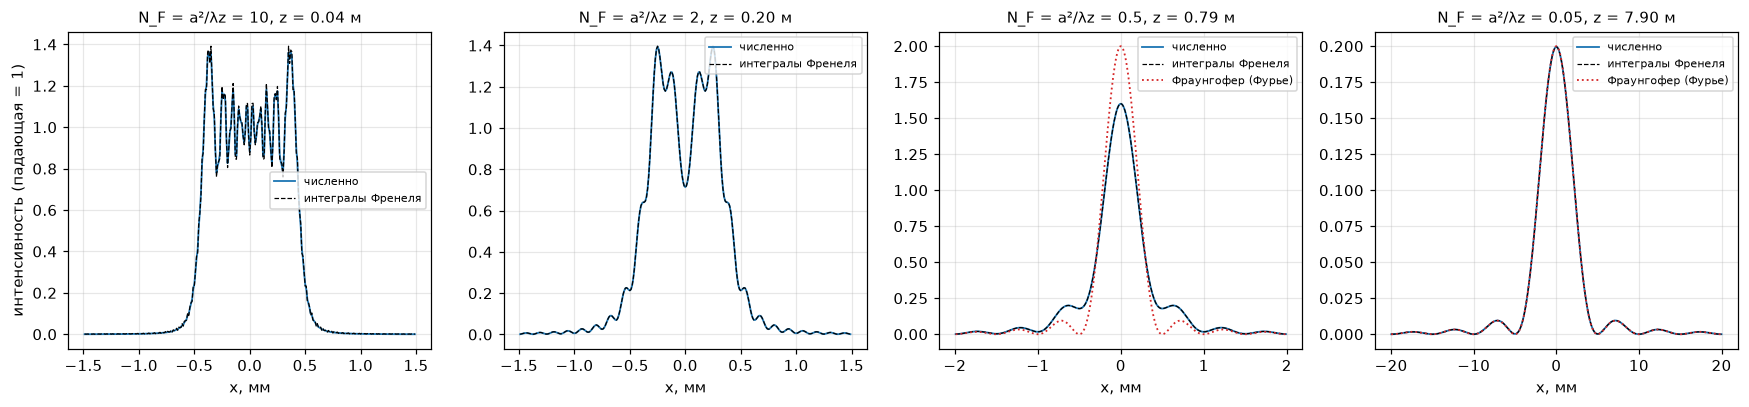

При N_F = 0.05 чирп exp(jπx²/λz) на краю щели поворачивает фазу на π·N_F = 0.16 рад → его можно отбросить, и остаётся чистое преобразование Фурье апертуры


In [7]:
# дифракция на щели шириной 2a: численно (чирп в спектре) против интегралов Френеля
NX, DX = 2 ** 16, 10e-6
xg = (np.arange(NX) - NX // 2) * DX
u0 = (np.abs(xg) <= SLIT_A + 1e-12).astype(complex)
u0[np.isclose(np.abs(xg), SLIT_A)] = 0.5                           # край щели попадает на отсчёт: вес ½ (правило трапеций)
def slit_analytic(x, z, a=SLIT_A):
    k = np.sqrt(2 / (LAM * z)); S1, C1 = fresnel(k * (-a - x)); S2, C2 = fresnel(k * (a - x))
    return 0.5 * ((C2 - C1) ** 2 + (S2 - S1) ** 2)
NFs = [10, 2, 0.5, 0.05]
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a_, nf in zip(ax, NFs):
    z = SLIT_A ** 2 / (LAM * nf)
    I = np.abs(fresnel_prop(u0, DX, z)) ** 2; Ia = slit_analytic(xg, z)
    span = max(3 * SLIT_A, 4 * LAM * z / (2 * SLIT_A)); m = np.abs(xg) < span
    a_.plot(xg[m] * 1e3, I[m], "C0", lw=1.2, label="численно"); a_.plot(xg[m] * 1e3, Ia[m], "k--", lw=0.8, label="интегралы Френеля")
    if nf < 1:
        Ifr = (2 * SLIT_A) ** 2 / (LAM * z) * np.sinc(2 * SLIT_A * xg / (LAM * z)) ** 2
        a_.plot(xg[m] * 1e3, Ifr[m], "C3:", lw=1.2, label="Фраунгофер (Фурье)")
        err_fr = np.abs(I[m] - Ifr[m]).max() / Ifr.max()
    else:
        err_fr = np.nan
    a_.set_xlabel("x, мм"); a_.legend(fontsize=7)
    a_.set_title(f"N_F = a²/λz = {nf:g}, z = {z:.2f} м", fontsize=10)
    print(f"  N_F = {nf:5g}: z = {z:6.3f} м, ошибка относительно интегралов Френеля: СКО {np.sqrt(np.mean((I - Ia)**2))/Ia.max():.1e}, max {np.abs(I - Ia).max()/Ia.max():.1e} от пика; отличие от Фраунгофера {err_fr:.1e}")
ax[0].set_ylabel("интенсивность (падающая = 1)")
plt.tight_layout(); plt.show()

# Фраунгофер как частный случай: Френель = чирп · Фурье · чирп
z = SLIT_A ** 2 / (LAM * 0.05)
ch = np.exp(1j * np.pi * xg ** 2 / (LAM * z))
print(f"При N_F = 0.05 чирп exp(jπx²/λz) на краю щели поворачивает фазу на π·N_F = {np.pi*0.05:.2f} рад → его можно отбросить, и остаётся чистое преобразование Фурье апертуры")

## 6. Дискретный Френель: эффект Тальбота и чирп → дельта
**Эффект Тальбота** (1836) — самое наглядное проявление квадратичной фазы. Периодическая решётка с периодом $d$ состоит из гармоник $m/d$. Каждая при распространении получает фазу $e^{-j\pi\lambda zm^2/d^2}$. На расстоянии $z_T=2d^2/\lambda$ эта фаза равна $e^{-j2\pi m^2}=1$ **для всех $m$ сразу**, и решётка воспроизводит себя без линзы. На $z_T/2$ фаза $(-1)^{m^2}=(-1)^m$ — копия, сдвинутая на полпериода. Между ними — «ковёр» из дробных копий. Численно восстановление точное: $10^{-16}$.

**Дискретное преобразование Френеля** (DFnT) — та же операция на сетке из $N$ отсчётов: $\Phi=F^H\Gamma F$, $\Gamma=\mathrm{diag}(e^{-j\pi k^2/N})$. Его базисные функции — дискретные чирпы $e^{-j\pi(n-m)^2/N}$ со сдвигом $m$. Это ровно базис OCDM (`ocdm_sim`), а AFDM (`afdm_sim`) — тот же DFnT с подстраиваемой скоростью чирпа. Поэтому:
* **согласованный чирп** — одна базисная функция; DFnT собирает его в один коэффициент (100 % энергии), а DFT размазывает по всем бинам равномерно;
* **чирп со скоростью 0.8/N** — уже не базисная функция: DFnT сжимает его лишь частично, в «полку» из ~45 отсчётов. Френель — это сжатие ЛЧМ-импульса **согласованным** фильтром, как в радаре и в демодуляторе LoRa (`lora_sim`).

Преобразования Френеля образуют группу: $\Phi_\alpha\Phi_\beta=\Phi_{\alpha+\beta}$ — распространение на $z_1$, а потом на $z_2$ равно распространению на $z_1+z_2$. Фурье в этом ряду — «бесконечное расстояние», а дробное преобразование Фурье (FrFT) соединяет их непрерывно.

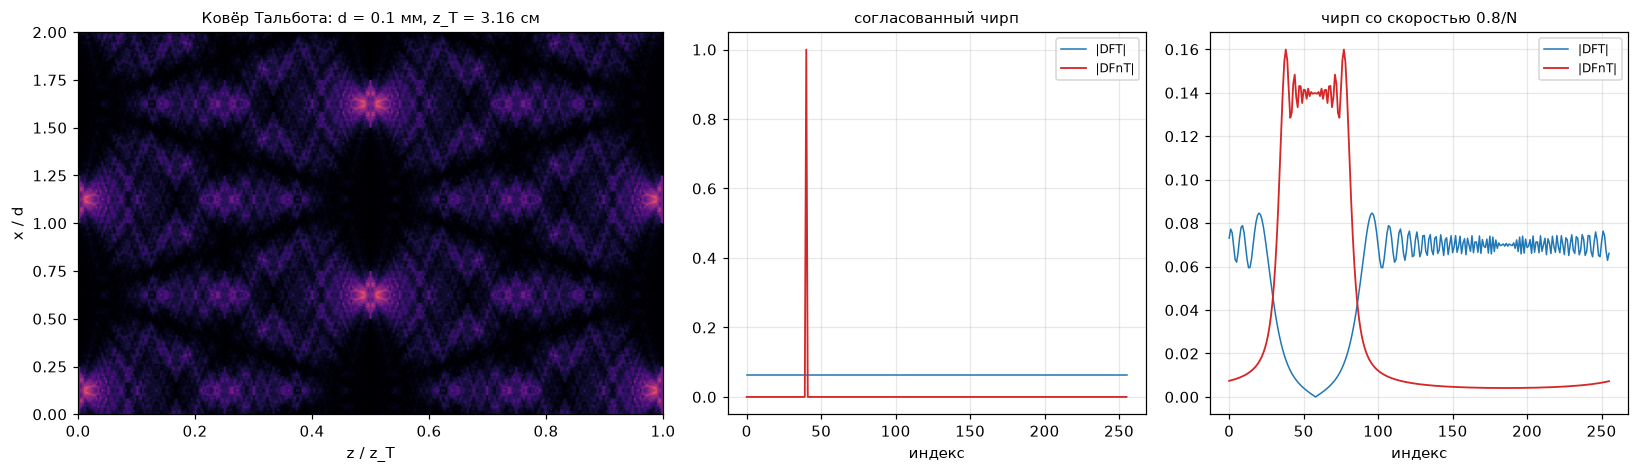

Тальбот: max|I(z_T) − I(0)| = 2.2e-16; на z_T/2 картина сдвинута на полпериода: ошибка 4.4e-16
  причина: гармоника m решётки получает фазу exp(−jπλz·m²/d²), на z_T это exp(−j2πm²) = 1 для всех m
Доля энергии в одном коэффициенте: согласованный чирп — DFT 0.004, DFnT 1.000 (в индексе 40); рассогласованный — DFnT 0.026
Френель — группа: Φ_α·Φ_β = Φ_(α+β), max ошибка 3.4e-15; распространение на z₁ и затем z₂ = на z₁ + z₂


In [8]:
# эффект Тальбота: периодическая решётка воспроизводит себя на z_T = 2d²/λ
PER, SPP = 8, 256
NT = PER * SPP; dxt = GRAT_D / SPP
xt = np.arange(NT) * dxt
grat = ((np.arange(NT) % SPP) < SPP // 4).astype(complex)               # щели шириной d/4
zT = 2 * GRAT_D ** 2 / LAM
zs = np.linspace(0, zT, 301)
carpet = np.array([np.abs(fresnel_prop(grat, dxt, z)) ** 2 for z in zs])
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.4, 1, 1]})
ax[0].imshow(carpet[:, :2 * SPP].T, aspect="auto", origin="lower", extent=[0, 1, 0, 2], cmap="magma", vmax=3); ax[0].grid(False)
ax[0].set_xlabel("z / z_T"); ax[0].set_ylabel("x / d")
ax[0].set_title(f"Ковёр Тальбота: d = {GRAT_D*1e3:g} мм, z_T = {zT*100:.2f} см", fontsize=10)
I0 = np.abs(grat) ** 2
err_T = np.abs(carpet[-1] - I0).max()
err_half = np.abs(carpet[150] - np.roll(I0, SPP // 2)).max()

# дискретное преобразование Френеля: чирп → дельта
M6 = 256; n6 = np.arange(M6)
chirp_m = np.exp(-1j * np.pi * (n6 - 40) ** 2 / M6) / np.sqrt(M6)       # чирп со скоростью ровно 1/N, сдвиг 40
chirp_x = np.exp(-1j * np.pi * 0.8 * (n6 - 40) ** 2 / M6) / np.sqrt(M6)  # скорость 0.8/N — рассогласован
for a_, sig, nm in ((ax[1], chirp_m, "согласованный чирп"), (ax[2], chirp_x, "чирп со скоростью 0.8/N")):
    a_.plot(n6, np.abs(np.fft.fft(sig)) / np.sqrt(M6), "C0", lw=1, label="|DFT|")
    a_.plot(n6, np.abs(dfnt(sig)), "C3", lw=1.2, label="|DFnT|")
    a_.set_xlabel("индекс"); a_.legend(fontsize=8); a_.set_title(nm, fontsize=10)
plt.tight_layout(); plt.show()

print(f"Тальбот: max|I(z_T) − I(0)| = {err_T:.1e}; на z_T/2 картина сдвинута на полпериода: ошибка {err_half:.1e}")
print(f"  причина: гармоника m решётки получает фазу exp(−jπλz·m²/d²), на z_T это exp(−j2πm²) = 1 для всех m")
pk = lambda c: np.max(np.abs(c) ** 2) / np.sum(np.abs(c) ** 2)
print(f"Доля энергии в одном коэффициенте: согласованный чирп — DFT {pk(np.fft.fft(chirp_m)):.3f}, DFnT {pk(dfnt(chirp_m)):.3f} (в индексе {np.argmax(np.abs(dfnt(chirp_m)))}); рассогласованный — DFnT {pk(dfnt(chirp_x)):.3f}")
print(f"Френель — группа: Φ_α·Φ_β = Φ_(α+β), max ошибка {np.abs(dfnt(dfnt(chirp_x, 0.3), 0.5) - dfnt(chirp_x, 0.8)).max():.1e}; распространение на z₁ и затем z₂ = на z₁ + z₂")

## 7. Каждому базису — свой сигнал: разреженность и шумоподавление
Три класса сигналов, три ортонормированных базиса. Для каждой пары:
* **K99** — сколько крупнейших коэффициентов несут 99 % энергии (меньше — лучше сжатие);
* **шумоподавление**: шум с SNR 5 дБ, затем все коэффициенты с $|c|<\sigma\sqrt{2\ln N}$ обнуляются (порог Донохо–Джонстона, один и тот же для всех базисов) и делается обратное преобразование.

Оба числа — одно и то же свойство. Ортонормированный базис превращает белый шум в белый шум с той же $\sigma$, поэтому шум раскладывается во **все** $N$ коэффициентов поровну. Сигнал же в «своём» базисе сосредоточен в немногих крупных коэффициентах, и порог отделяет их от шума. В «чужом» базисе сигнал размазан по тысячам мелких коэффициентов, тонущих в шуме, и порог убивает его вместе с шумом.

Диагональ таблицы выигрывает везде: тоны — Фурье (25 коэффициентов, 17 дБ), ступени — вейвлеты (46, 14.9 дБ), чирп — Френель (1 коэффициент, 34 дБ). Ни один базис не универсален. Поэтому в связи форма сигнала выбирается под канал (`ofdm_sim` против `ocdm_sim` против `otfs_sim`), а в сжатии — под класс изображений (DCT в JPEG, вейвлеты в JPEG 2000).

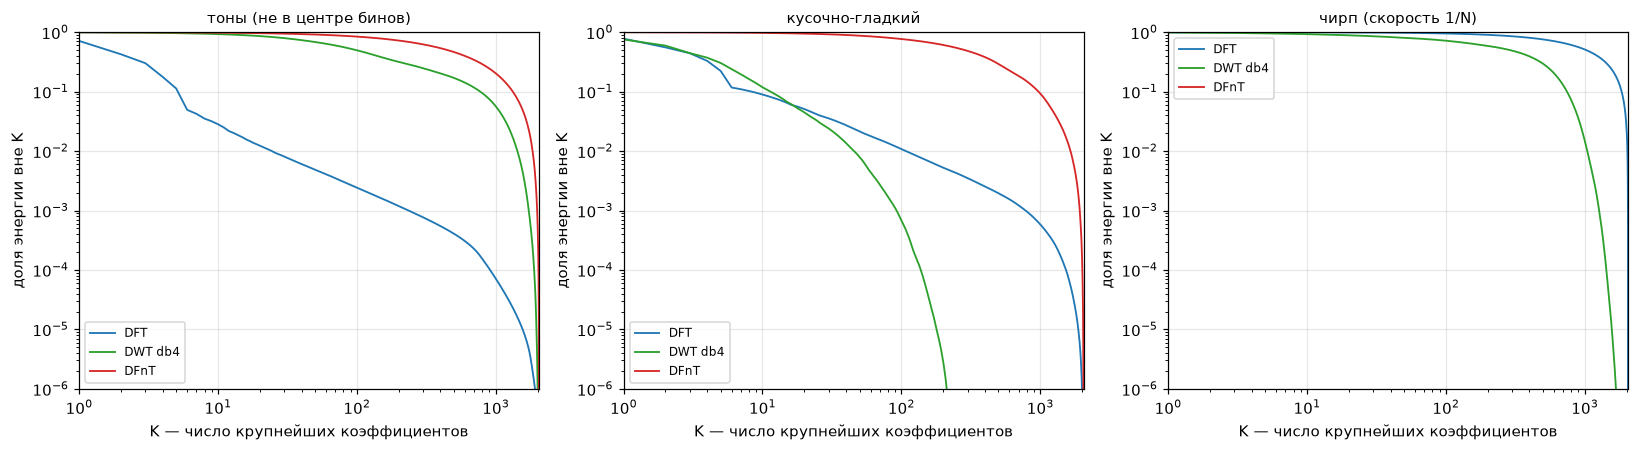

Число коэффициентов для 99 % энергии (из 2048) и SNR после порога (на входе 5 дБ):
                                           DFT           DWT db4              DFnT
тоны (не в центре бинов)         25 /  17.0 dB     1431 /   3.2 dB     1842 /   0.4 dB  
кусочно-гладкий                 108 /  13.0 dB       46 /  14.9 dB     1652 /   1.1 dB  
чирп (скорость 1/N)            2028 /  -0.0 dB     1043 /   1.0 dB        1 /  34.0 dB  


In [9]:
# три класса сигналов × три ортонормированных базиса: разреженность и подавление шума
u = np.arange(N)
SIGS = {
    "тоны (не в центре бинов)": np.cos(2 * np.pi * 50.3 * t) + 0.7 * np.cos(2 * np.pi * 120.7 * t) + 0.5 * np.cos(2 * np.pi * 333.1 * t),
    "кусочно-гладкий": X_PW - X_PW.mean(),
    "чирп (скорость 1/N)": np.exp(-1j * np.pi * (u - 300) ** 2 / N),
}
def to_c(x, kind):
    if kind == "DFT": return np.fft.fft(x) / np.sqrt(N)
    if kind == "DWT db4": return np.concatenate(wavedec(x, "db4", 8))
    return dfnt(x)
def from_c(c, kind):
    if kind == "DFT": return np.fft.ifft(c) * np.sqrt(N)
    if kind == "DWT db4":
        sizes = [N >> 8] + [N >> j for j in range(8, 0, -1)]; parts = np.split(c, np.cumsum(sizes)[:-1])
        return waverec(parts, "db4")
    return idfnt(c)
KINDS = ["DFT", "DWT db4", "DFnT"]
SNR_IN = 5
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
K99 = np.zeros((3, 3), int); SNRo = np.zeros((3, 3))
for i, ((nm, x), a_) in enumerate(zip(SIGS.items(), ax)):
    px = np.mean(np.abs(x) ** 2); sig = np.sqrt(px / 10 ** (SNR_IN / 10))
    cplx = np.iscomplexobj(x)
    noise = sig * (rng.standard_normal(N) + 1j * rng.standard_normal(N)) / np.sqrt(2) if cplx else sig * rng.standard_normal(N)
    for j, (kd, c_) in enumerate(zip(KINDS, ("C0", "C2", "C3"))):
        c = to_c(x.astype(complex), kd); e = np.sort(np.abs(c) ** 2)[::-1]; ce = np.cumsum(e) / e.sum()
        K99[i, j] = np.searchsorted(ce, 0.99) + 1
        a_.loglog(np.arange(1, N + 1), np.maximum(1 - ce, 1e-12), c_, lw=1.2, label=kd)
        cn = to_c((x + noise).astype(complex), kd)
        cn = np.where(np.abs(cn) > sig * np.sqrt(2 * np.log(N)), cn, 0)    # жёсткий порог σ√(2 ln N)
        xr = from_c(cn, kd); xr = xr if cplx else xr.real
        SNRo[i, j] = 10 * np.log10(px / np.mean(np.abs(xr - x) ** 2))
    a_.set_ylim(1e-6, 1); a_.set_xlim(1, N); a_.set_xlabel("K — число крупнейших коэффициентов")
    a_.set_ylabel("доля энергии вне K"); a_.legend(fontsize=8); a_.set_title(nm, fontsize=10)
plt.tight_layout(); plt.show()

print(f"Число коэффициентов для 99 % энергии (из {N}) и SNR после порога (на входе {SNR_IN} дБ):")
print(f"{'':28s}" + "".join(f"{k:>18s}" for k in KINDS))
for i, nm in enumerate(SIGS):
    print(f"{nm:28s}" + "".join(f"{K99[i, j]:7d} / {SNRo[i, j]:5.1f} dB  " for j in range(3)))

## Сравнение

| | Фурье (DFT) | STFT | CWT (Морле) | DWT (Добеши) | Френель (DFnT) |
|---|---|---|---|---|---|
| базис | синусоиды | синусоиды × окно | растянутые волночки | диадические волночки | чирпы |
| ортонормированный | да | нет (фрейм) | нет (избыточно) | да | да |
| коэффициентов на $N$ отсчётов | $N$ | $N\cdot$(перекрытие) | $N\cdot$(число масштабов) | $N$ | $N$ |
| сложность | $N\log N$ | $N\log L$ на кадр | $N\log N$ на масштаб | $N$ | $N\log N$ |
| частотно-временные клетки | вся полоса × всё время | одинаковые | $\Delta f\propto f$ | $\Delta f\propto f$, диадически | наклонные (вдоль ЛЧМ) |
| разрежает | тоны | — | — | кусочно-гладкое | чирпы |
| диагонализует | LTI-каналы (свёртку) | — | — | — | распространение в оптике |
| в связи | OFDM, OFDMA | спектрограммы, анализ | анализ, радары | wavelet-OFDM (PLC), сжатие | OCDM, AFDM, LoRa |

**Главное.**
- Все пять — один вопрос: по каким эталонным сигналам раскладывать.
- Фурье диагонализует **свёртку**, поэтому LTI-канал в нём — просто умножение, и OFDM строится на Фурье.
- Френель диагонализует **квадратичную фазу**, поэтому сжимает чирпы и описывает дифракцию.
- Вейвлеты ничего не диагонализуют, зато **адаптируют разрешение** к масштабу и делают разреженными сигналы, гладкие везде, кроме немногих точек.

## Что покрутить
- В разделе 1 сдвиньте слабый тон на 101.5 Гц — его не отделяет ни одно окно: он внутри главного лепестка сильного тона.
- `W0 = 12` — тоны 50 и 62 Гц на скалограмме разрешаются, но щелчки размазываются вдвое. `W0 = 3` — наоборот.
- В разделе 4 замените `"db4"` на `"haar"` — ступеньки описываются ещё компактнее (Хаар сам ступенька), а горб и излом — хуже; сравните K99.
- `SLIT_A = 2e-3` — при тех же $N_F$ все расстояния растут в 16 раз; картины те же — это масштабная инвариантность Френеля.
- `GRAT_D = 0.2e-3` — расстояние Тальбота растёт в 4 раза: $z_T\propto d^2$.
- В разделе 7 добавьте шумоподавление в DFnT с другой скоростью `alpha` — посмотрите, насколько быстро разреженность чирпа разваливается при рассогласовании.